# Predviđanje potrošnje energije kućanskih uređaja
### Projekt iz kolegija: Uvod u umjetnu inteligenciju

**Problem:** Regresijski problem predviđanja potrošnje energije kućanskih uređaja (u Wh) na temelju temperature i vlažnosti u različitim prostorijama kuće, te vanjskih vremenskih uvjeta.

**Dataset:** [Appliances Energy Prediction](https://www.kaggle.com/datasets/loveall/appliances-energy-prediction) — 19,735 mjerenja u razmaku od 10 minuta, kroz 4.5 mjeseca (siječanj-svibanj 2016), 29 značajki.

## 2. Prikupljanje i obrada podataka

### 2.1 Prikupljanje podataka

Podaci su preuzeti s platforme Kaggle / UCI Machine Learning Repository, iz dataset-a **"Appliances Energy Prediction"** (autor: Luis Candanedo, 2017). Podaci su prikupljeni u niskoenergetskoj kući u Belgiji — temperatura i vlažnost su mjereni ZigBee bežičnom senzorskom mrežom u 9 prostorija, a vanjski vremenski podaci preuzeti su s obližnje meteorološke postaje (zračna luka Chievres) i spojeni s podacima kuće preko stupca datuma/vremena. Mjerenja su zabilježena svakih 10 minuta kroz period od 4.5 mjeseca.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv("KAG_energydata_complete.csv")
print("Dimenzije dataseta:", df.shape)
df.head()

Dimenzije dataseta: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9           19

In [ ]:
# Provjera nedostajućih vrijednosti i duplikata
print("Broj nedostajućih vrijednosti po koloni:")
print(df.isnull().sum().sum(), "ukupno nedostajućih vrijednosti")
print()
print("Broj dupliciranih redaka:", df.duplicated().sum())

Broj nedostajućih vrijednosti po koloni:
0 ukupno nedostajućih vrijednosti

Broj dupliciranih redaka: 0


**Zaključak:** Dataset ne sadrži nedostajuće vrijednosti niti duplikate.

### 2.2 Čišćenje podataka

Dataset sadrži dvije posebne kolone, `rv1` i `rv2` — to su **namjerno ubačene nasumične varijable** (autor dataseta ih je dodao kako bi se moglo testirati prepoznaju li modeli za odabir značajki nebitne, šumovite varijable). Provjerimo njihov sadržaj prije nego odlučimo što s njima.

In [ ]:
# Provjera rv1 i rv2
print(df[['rv1', 'rv2']].head())
print()
print("Jesu li rv1 i rv2 identične u svakom retku?", (df['rv1'] == df['rv2']).all())

         rv1        rv2
0  13.275433  13.275433
1  18.606195  18.606195
2  28.642668  28.642668
3  45.410389  45.410389
4  10.084097  10.084097

Jesu li rv1 i rv2 identične u svakom retku? True


**Zapažanje:** `rv1` i `rv2` su potpuno identične, nasumične vrijednosti bez ikakve stvarne veze s potrošnjom energije. Budući da nose isključivo šum, izbacujemo ih iz dataseta već u ovoj fazi.

In [ ]:
df = df.drop(columns=['rv1', 'rv2'])
print("Preostale kolone:", df.shape[1])

Preostale kolone: 27


**Obrada stupca datuma:** Stupac `date` je trenutno tekstualni zapis vremena. Iz njega izdvajamo korisne vremenske značajke — sat u danu i dan u tjednu — jer je realno za očekivati da potrošnja energije ovisi o dobu dana (npr. navečer se koristi više uređaja) i je li radni dan ili vikend.

In [ ]:
df['date'] = pd.to_datetime(df['date'])
df['hour'] = df['date'].dt.hour
df['dayofweek'] = df['date'].dt.dayofweek  # 0 = ponedjeljak, 6 = nedjelja
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)

df[['date', 'hour', 'dayofweek', 'is_weekend']].head()

,date,hour,dayofweek,is_weekend
0,2016-01-11 17:00:00,17,0,0
1,2016-01-11 17:10:00,17,0,0
2,2016-01-11 17:20:00,17,0,0
3,2016-01-11 17:30:00,17,0,0
4,2016-01-11 17:40:00,17,0,0


In [ ]:
# date stupac više ne treba u izvornom obliku - zadržavamo izvedene značajke
df = df.drop(columns=['date'])
df.head()

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,hour,dayofweek,is_weekend
0,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,17,0,0
1,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,17,0,0
2,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,17,0,0
3,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,17,0,0
4,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,17,0,0


## 3. Analiza značajki

### 3.1 Istraživačka analiza podataka (EDA)



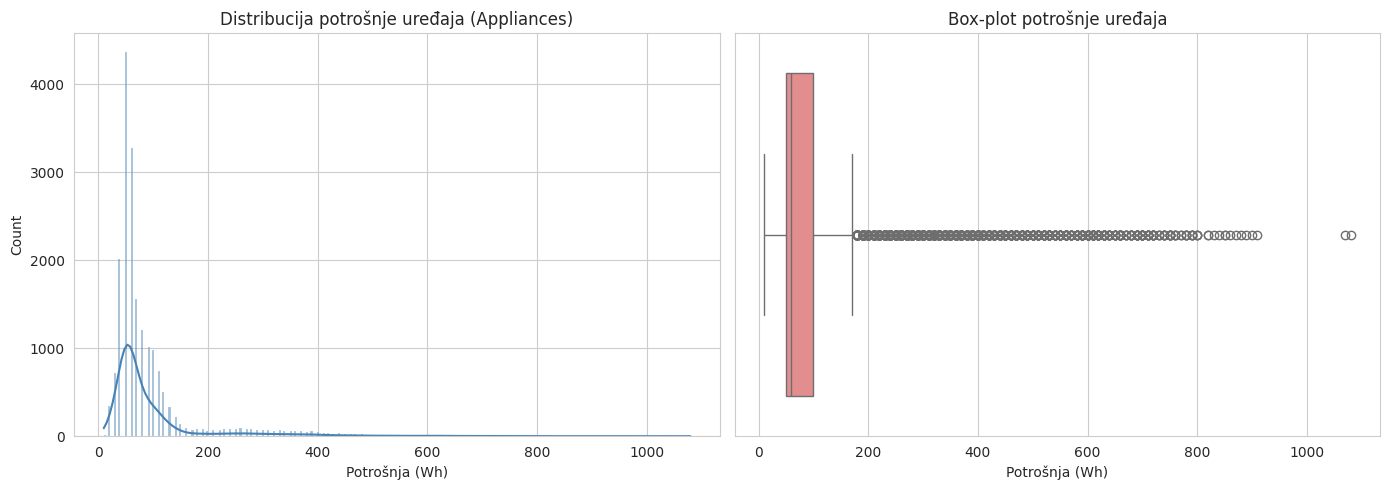

Skewness (zakošenost): 3.39


In [ ]:
# Distribucija ciljne varijable
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Appliances'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribucija potrošnje uređaja (Appliances)')
axes[0].set_xlabel('Potrošnja (Wh)')

sns.boxplot(x=df['Appliances'], ax=axes[1], color='lightcoral')
axes[1].set_title('Box-plot potrošnje uređaja')
axes[1].set_xlabel('Potrošnja (Wh)')

plt.tight_layout()
plt.show()

print("Skewness (zakošenost):", df['Appliances'].skew().round(2))

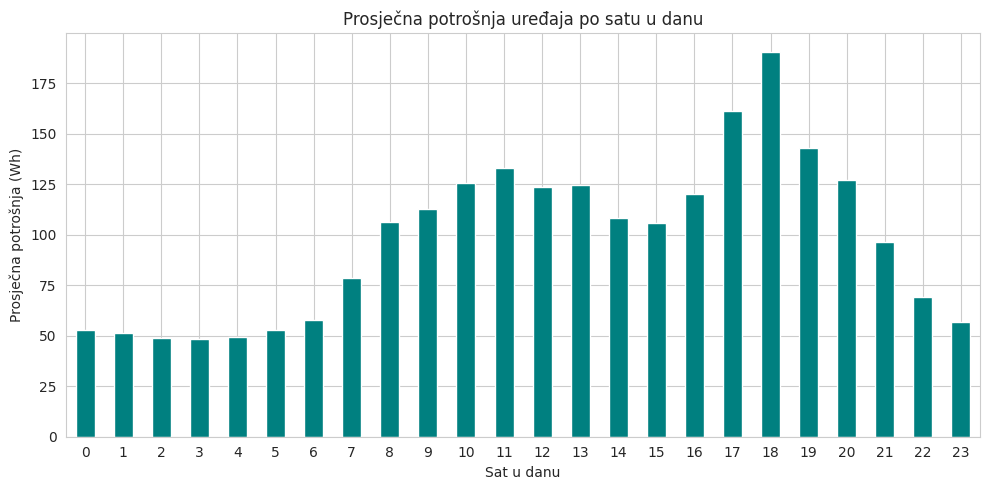

In [ ]:
# Potrošnja energije po satu u danu
hourly = df.groupby('hour')['Appliances'].mean()

plt.figure(figsize=(10, 5))
hourly.plot(kind='bar', color='teal', edgecolor='white')
plt.title('Prosječna potrošnja uređaja po satu u danu')
plt.xlabel('Sat u danu')
plt.ylabel('Prosječna potrošnja (Wh)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Zapažanje: Vidljiv je jasni dnevni obrazac — potrošnja je niža u ranim jutarnjim satima (2-6h), raste ujutro, blago opada poslijepodne, i dostiže vrhunac navečer (18-21h) kad su ukućani kod kuće i koriste više uređaja. Ovo potvrđuje da je hour korisna značajka za model.

In [1]:
# Potrošnja radnim danom vs vikend
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

weekend_labels = {0: 'Radni dan', 1: 'Vikend'}
df['weekend_label'] = df['is_weekend'].map(weekend_labels)
sns.boxplot(data=df, x='weekend_label', y='Appliances', ax=axes[0])
axes[0].set_title('Potrošnja: Radni dan vs Vikend')
axes[0].set_xlabel('')

# Potrošnja po danu u tjednu
day_labels = ['Pon', 'Uto', 'Sri', 'Čet', 'Pet', 'Sub', 'Ned']
daily = df.groupby('dayofweek')['Appliances'].mean()
axes[1].bar(day_labels, daily.values, color='slateblue')
axes[1].set_title('Prosječna potrošnja po danu u tjednu')
axes[1].set_ylabel('Prosječna potrošnja (Wh)')

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

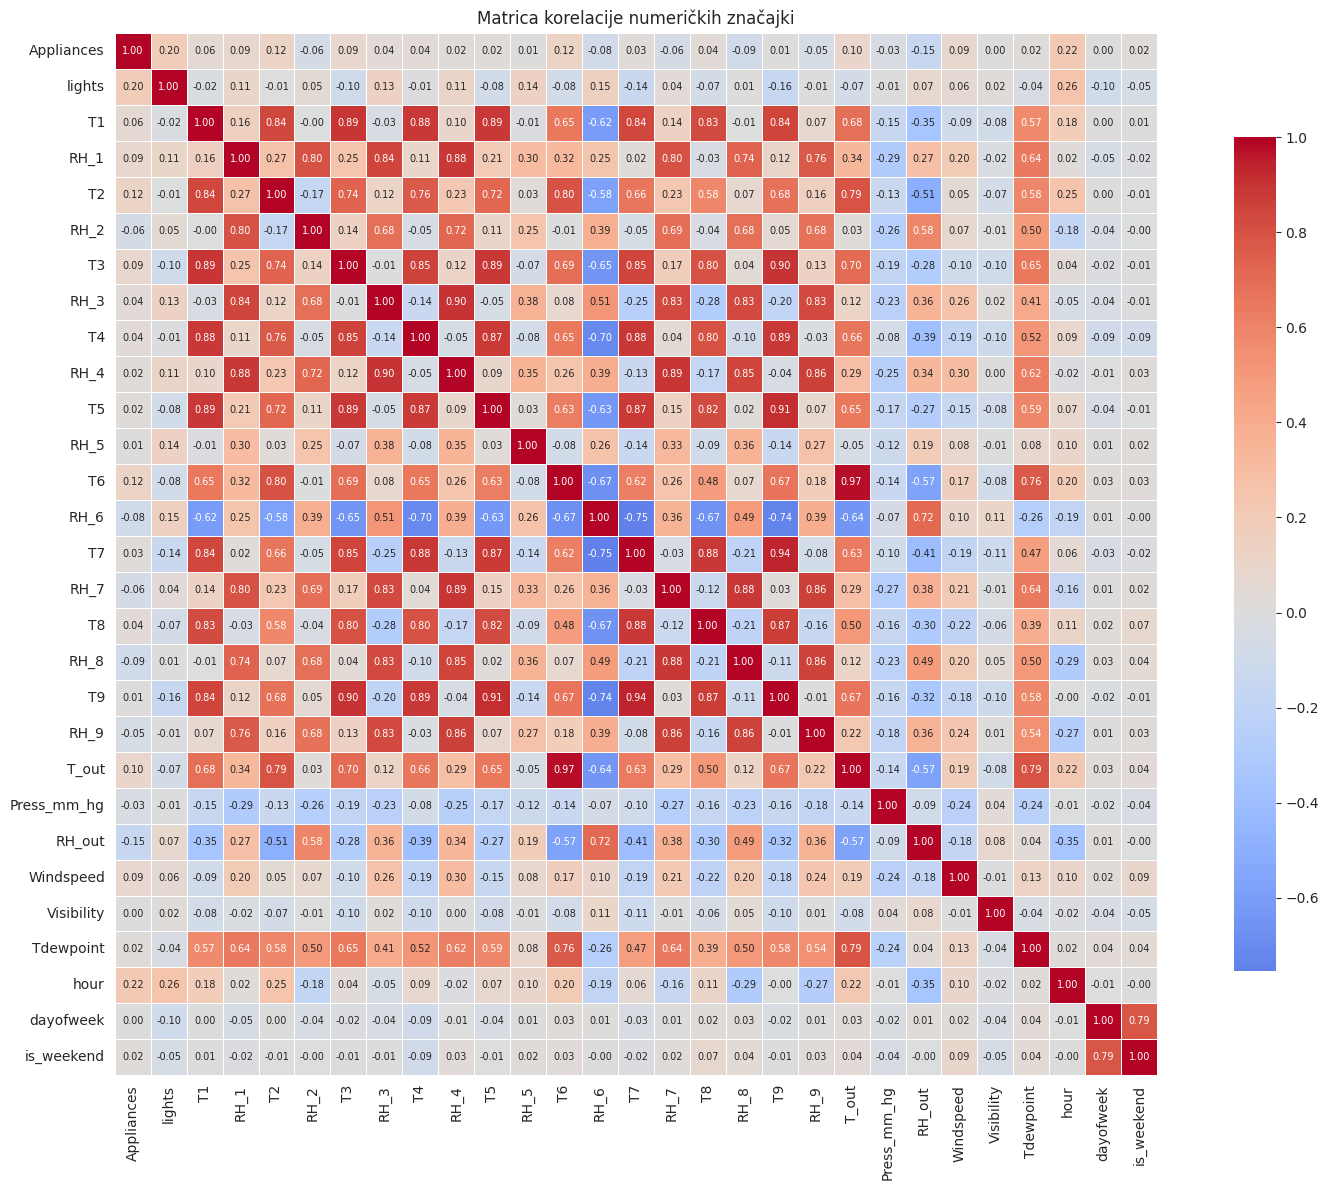

In [ ]:
# Matrica korelacije
numeric_cols = df.drop(columns=['weekend_label']).select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.4, cbar_kws={"shrink": 0.8}, annot_kws={"size": 7})
plt.title('Matrica korelacije numeričkih značajki')
plt.tight_layout()
plt.show()

In [ ]:
# Korelacija svih značajki s Appliances, sortirano
price_corr = corr_matrix['Appliances'].drop('Appliances').sort_values(ascending=False)
print("Korelacija značajki s potrošnjom (sortirano):")
print(price_corr.round(3))

Korelacija značajki s potrošnjom (sortirano):
hour           0.217
lights         0.197
T2             0.120
T6             0.118
T_out          0.099
Windspeed      0.087
RH_1           0.086
T3             0.085
T1             0.055
T4             0.040
T8             0.040
RH_3           0.036
T7             0.026
T5             0.020
is_weekend     0.017
RH_4           0.017
Tdewpoint      0.015
T9             0.010
RH_5           0.007
dayofweek      0.003
Visibility     0.000
Press_mm_hg   -0.035
RH_9          -0.051
RH_7          -0.056
RH_2          -0.060
RH_6          -0.083
RH_8          -0.094
RH_out        -0.152
Name: Appliances, dtype: float64


Zapažanje: Temperatura u prostoriji za glačanje (T6) i kuhinjska temperatura (T1) pokazuju pozitivnu korelaciju s potrošnjom — toplije prostorije upućuju na aktivnost uređaja koji generiraju toplinu (perilica, glačalo, štednjak). Vanjska temperatura (T_out) ima negativnu korelaciju — hladniji dani znače više grijanja i veću potrošnju. rv1 i rv2 su već izbačene, ali korelacijska analiza ionako potvrđuje da takve nasumične varijable ne bi imale nikakvu prediktivnu vrijednost.

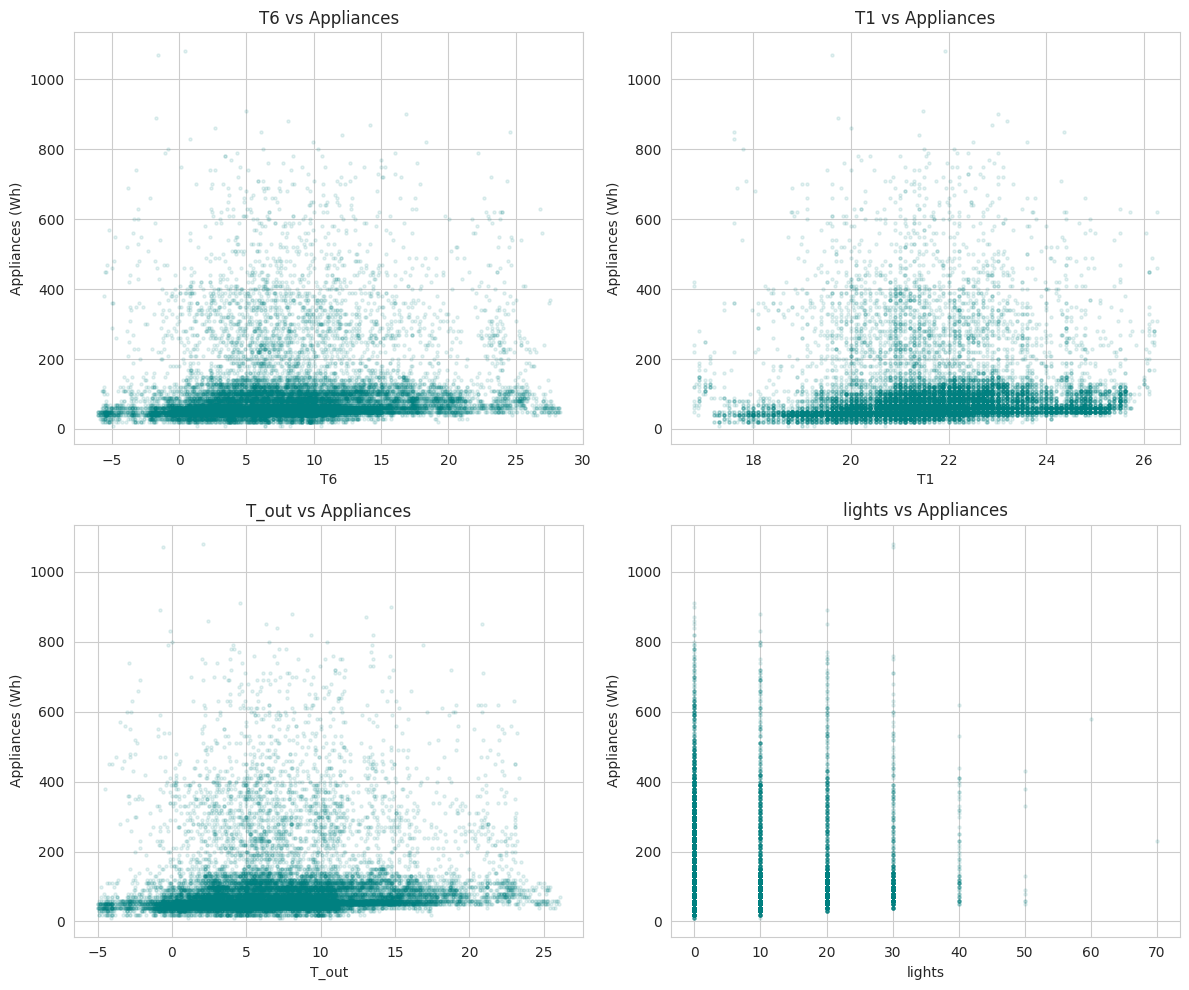

In [ ]:
# Scatter plotovi top značajki naspram potrošnje
top_features = ['T6', 'T1', 'T_out', 'lights']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(df[feature], df['Appliances'], alpha=0.1, color='teal', s=5)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Appliances (Wh)')
    axes[i].set_title(f'{feature} vs Appliances')

plt.tight_layout()
plt.show()

### 3.2 Odabir značajki

Na temelju korelacijske analize i EDA vizualizacija odabrane su značajke koje pokazuju vidljiv utjecaj na potrošnju energije. Izbačene su: lights (potrošnja rasvjete — ovo je posebna varijabla koja nije karakteristika prostora nego direktno mjerenje, što bi model mogao "varati"), dayofweek (dan u tjednu, zamijenjen s is_weekend koji sažima istu informaciju jednostavnije), te sve RH vlažnosti koje imaju nisku korelaciju s potrošnjom.

In [ ]:
# Odabrane značajke za model
selected_features = [
    'T1', 'T2', 'T3', 'T6', 'T7', 'T8', 'T9',   # temperature po prostorijama
    'T_out', 'Tdewpoint', 'Windspeed', 'Visibility',  # vanjski vremenski uvjeti
    'RH_out', 'Press_mm_hg',                           # vanjska vlažnost i tlak
    'hour', 'is_weekend'                               # vremenske značajke
]

print("Odabrane značajke:", selected_features)
print("Broj odabranih značajki:", len(selected_features))

df_model = df[selected_features + ['Appliances']].copy()
df_model.head()

Odabrane značajke: ['T1', 'T2', 'T3', 'T6', 'T7', 'T8', 'T9', 'T_out', 'Tdewpoint', 'Windspeed', 'Visibility', 'RH_out', 'Press_mm_hg', 'hour', 'is_weekend']
Broj odabranih značajki: 15


,T1,T2,T3,T6,T7,T8,T9,T_out,Tdewpoint,Windspeed,Visibility,RH_out,Press_mm_hg,hour,is_weekend,Appliances
0,19.89,19.2,19.79,7.026667,17.200000,18.2,17.033333,6.600000,5.3,7.000000,63.000000,92.0,733.5,17,0,60
1,19.89,19.2,19.79,6.833333,17.200000,18.2,17.066667,6.483333,5.2,6.666667,59.166667,92.0,733.6,17,0,60
2,19.89,19.2,19.79,6.560000,17.200000,18.2,17.000000,6.366667,5.1,6.333333,55.333333,92.0,733.7,17,0,50
3,19.89,19.2,19.79,6.433333,17.133333,18.1,17.000000,6.250000,5.0,6.000000,51.500000,92.0,733.8,17,0,50
4,19.89,19.2,19.79,6.366667,17.200000,18.1,17.000000,6.133333,4.9,5.666667,47.666667,92.0,733.9,17,0,60


## 4. Izbor i implementacija modela

### 4.1 Izbor modela

Odabrana su ista tri modela kao i u prethodnom projektu, što omogućuje metodološki konzistentnu usporedbu jednostavnog linearnog pristupa s nelinearnim modelima:

1. Linearna regresija — najjednostavniji baseline model, pretpostavlja linearan odnos između značajki i potrošnje energije.
2. Regresijsko stablo (Decision Tree Regressor) — hvata nelinearne obrasce postavljanjem pravila odlučivanja, ali sklon je prenaučenosti bez ograničenja dubine.
3. Random Forest Regressor — ansambl više stabala koji smanjuje varijancu i tipično daje stabilnije predikcije od pojedinačnog stabla.

### 4.2 Priprema podataka za modeliranje

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_model.drop(columns=['Appliances'])
y = df_model['Appliances']

print("Dimenzije X:", X.shape)
print("Značajke:", list(X.columns))

Dimenzije X: (19735, 15)
Značajke: ['T1', 'T2', 'T3', 'T6', 'T7', 'T8', 'T9', 'T_out', 'Tdewpoint', 'Windspeed', 'Visibility', 'RH_out', 'Press_mm_hg', 'hour', 'is_weekend']


In [ ]:
# Podjela na trening (80%) i test (20%) skup
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Veličina trening skupa:", X_train.shape)
print("Veličina test skupa:", X_test.shape)

Veličina trening skupa: (15788, 15)
Veličina test skupa: (3947, 15)


In [ ]:
# Standardizacija za linearnu regresiju
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

X_train_scaled.head()

,T1,T2,T3,T6,T7,T8,T9,T_out,Tdewpoint,Windspeed,Visibility,RH_out,Press_mm_hg,hour,is_weekend
0,-1.117535,-0.521432,-0.936016,0.522130,-1.307109,-2.000051,-1.148323,0.540910,0.992041,1.424184,-1.255203,0.381152,0.863704,0.072446,-0.622078
1,2.409418,2.524617,2.456153,2.766726,1.999713,1.363117,1.835628,2.874781,2.273160,-0.286316,-1.241097,-1.621760,-0.045041,0.793894,-0.622078
2,0.504076,0.540967,-0.152313,-0.226797,-0.461508,-0.746661,-0.439429,-0.153619,-0.852294,1.629444,0.141283,-1.062287,0.633127,0.216736,-0.622078
3,-1.179665,-1.432060,-0.831411,-0.839705,-1.023668,-0.780690,-0.543290,-0.998318,-0.606383,-1.244196,0.874791,0.974193,-1.898699,-0.360422,1.607516
4,-0.676407,-1.477591,-0.985827,-1.406180,0.204581,0.342257,-0.277867,-1.555193,-1.359982,-0.970516,-0.366530,0.839920,1.727238,-1.081870,1.607516


### 4.3 Implementacija modela

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

lin_reg = LinearRegression()
tree_reg = DecisionTreeRegressor(random_state=42, max_depth=8)
rf_reg = RandomForestRegressor(random_state=42, n_estimators=200, max_depth=10)

lin_reg.fit(X_train_scaled, y_train)
tree_reg.fit(X_train, y_train)
rf_reg.fit(X_train, y_train)

print("Svi modeli su uspješno trenirani.")

Svi modeli su uspješno trenirani.


### 4.4 Kros-validacija

Koristimo 5-struku kros-validaciju kako bismo ocijenili robusnost svakog modela.

In [ ]:
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_lin = cross_val_score(lin_reg, X_train_scaled, y_train, cv=kf, scoring='r2')
cv_scores_tree = cross_val_score(tree_reg, X_train, y_train, cv=kf, scoring='r2')
cv_scores_rf = cross_val_score(rf_reg, X_train, y_train, cv=kf, scoring='r2')

cv_results = pd.DataFrame({
    'Linearna regresija': cv_scores_lin,
    'Regresijsko stablo': cv_scores_tree,
    'Random Forest': cv_scores_rf
})

print("R² score po foldu:")
print(cv_results)
print()
print("Prosječni R² (± std. dev.) po modelu:")
for col in cv_results.columns:
    print(f"  {col}: {cv_results[col].mean():.4f} (± {cv_results[col].std():.4f})")

R² score po foldu:
   Linearna regresija  Regresijsko stablo  Random Forest
0            0.105948            0.188807       0.358449
1            0.110949            0.252887       0.393592
2            0.091373            0.196033       0.359675
3            0.114737            0.250652       0.405066
4            0.105727            0.203696       0.377747

Prosječni R² (± std. dev.) po modelu:
  Linearna regresija: 0.1057 (± 0.0089)
  Regresijsko stablo: 0.2184 (± 0.0309)
  Random Forest: 0.3789 (± 0.0206)


/tmp/ipykernel_599/965658122.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cv_melted, x='Model', y='R2_score', palette='Set3')


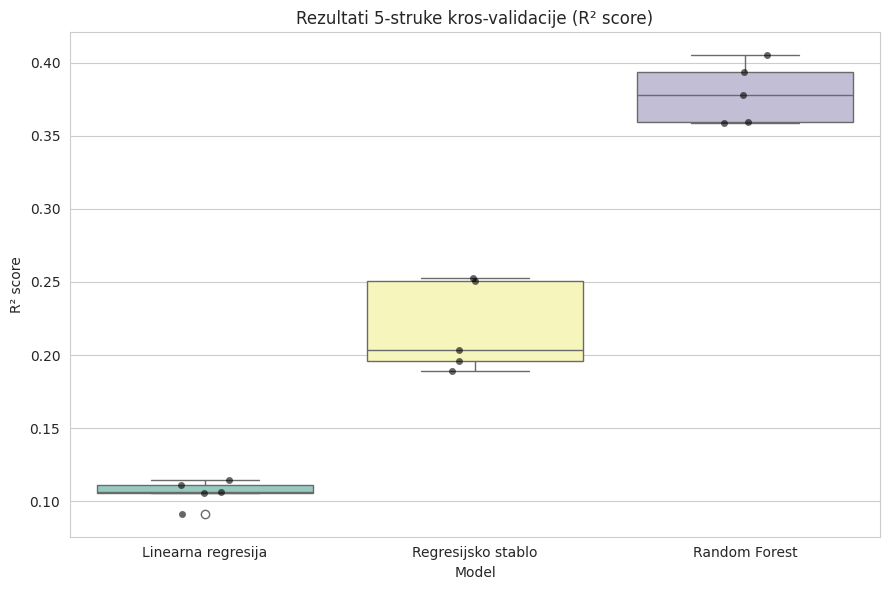

In [ ]:
# Vizualizacija kros-validacije
plt.figure(figsize=(9, 6))
cv_melted = cv_results.melt(var_name='Model', value_name='R2_score')
sns.boxplot(data=cv_melted, x='Model', y='R2_score', palette='Set3')
sns.stripplot(data=cv_melted, x='Model', y='R2_score', color='black', alpha=0.6, jitter=True)
plt.title('Rezultati 5-struke kros-validacije (R² score)')
plt.ylabel('R² score')
plt.tight_layout()
plt.show()

## 5. Evaluacija modela

### 5.1 Evaluacija performansi

Performanse modela na test skupu ocjenjujemo pomoću tri metrike: **RMSE** (kažnjava velike pogreške jače), **MAE** (srednja apsolutna pogreška u Wh) i **R²** (udio objašnjene varijance potrošnje).

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_model(model, X_test_data, y_test_data, name):
    y_pred = model.predict(X_test_data)
    rmse = np.sqrt(mean_squared_error(y_test_data, y_pred))
    mae = mean_absolute_error(y_test_data, y_pred)
    r2 = r2_score(y_test_data, y_pred)
    return {'Model': name, 'RMSE': round(rmse, 3), 'MAE': round(mae, 3), 'R2': round(r2, 4)}, y_pred

results = []
predictions = {}

res, pred = evaluate_model(lin_reg, X_test_scaled, y_test, 'Linearna regresija')
results.append(res); predictions['Linearna regresija'] = pred

res, pred = evaluate_model(tree_reg, X_test, y_test, 'Regresijsko stablo')
results.append(res); predictions['Regresijsko stablo'] = pred

res, pred = evaluate_model(rf_reg, X_test, y_test, 'Random Forest')
results.append(res); predictions['Random Forest'] = pred

results_df = pd.DataFrame(results)
results_df

,Model,RMSE,MAE,R2
0,Linearna regresija,94.349,54.664,0.1105
1,Regresijsko stablo,86.836,45.298,0.2465
2,Random Forest,77.346,40.154,0.4022


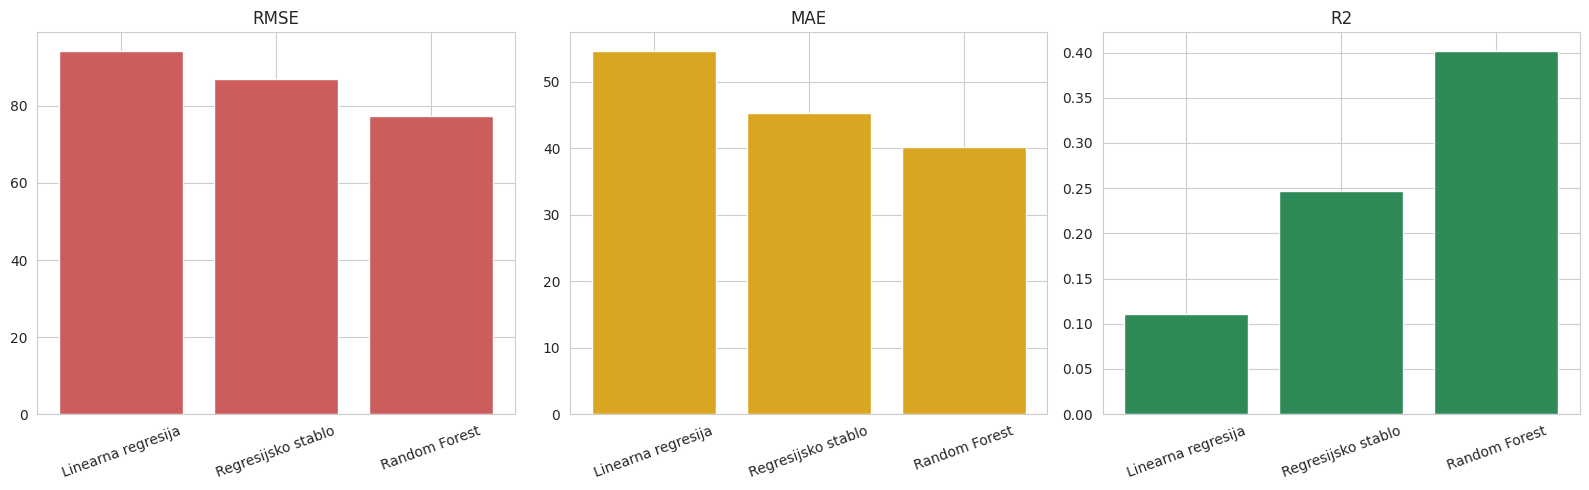

In [ ]:
# Usporedba metrika vizualno
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics = ['RMSE', 'MAE', 'R2']
colors_list = ['indianred', 'goldenrod', 'seagreen']

for i, metric in enumerate(metrics):
    axes[i].bar(results_df['Model'], results_df[metric], color=colors_list[i])
    axes[i].set_title(metric)
    axes[i].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

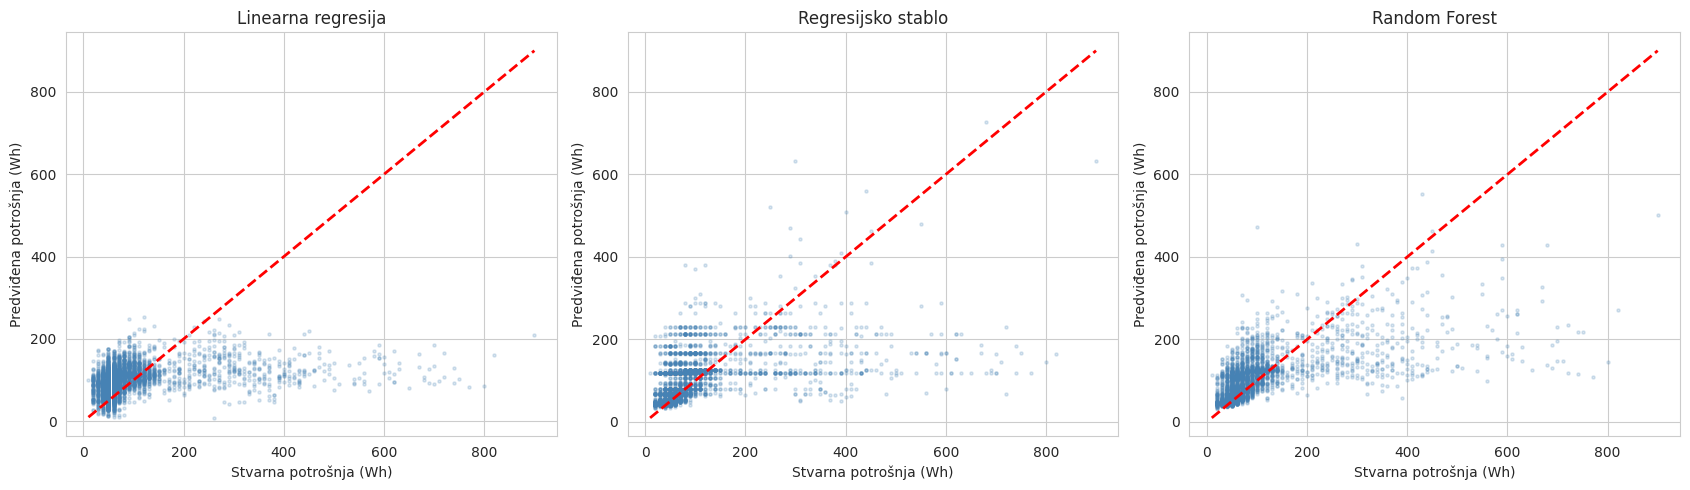

In [ ]:
# Predviđeno vs. stvarno
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for i, (name, pred) in enumerate(predictions.items()):
    axes[i].scatter(y_test, pred, alpha=0.2, color='steelblue', s=5)
    axes[i].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[i].set_xlabel('Stvarna potrošnja (Wh)')
    axes[i].set_ylabel('Predviđena potrošnja (Wh)')
    axes[i].set_title(name)

plt.tight_layout()
plt.show()

### 5.2 Usporedba modela

In [ ]:
summary = pd.DataFrame({
    'Model': results_df['Model'],
    'CV R2 (mean)': cv_results.mean().values.round(4),
    'CV R2 (std)': cv_results.std().values.round(4),
    'Test RMSE': results_df['RMSE'].values,
    'Test MAE': results_df['MAE'].values,
    'Test R2': results_df['R2'].values
})
summary

,Model,CV R2 (mean),CV R2 (std),Test RMSE,Test MAE,Test R2
0,Linearna regresija,0.1057,0.0089,94.349,54.664,0.1105
1,Regresijsko stablo,0.2184,0.0309,86.836,45.298,0.2465
2,Random Forest,0.3789,0.0206,77.346,40.154,0.4022


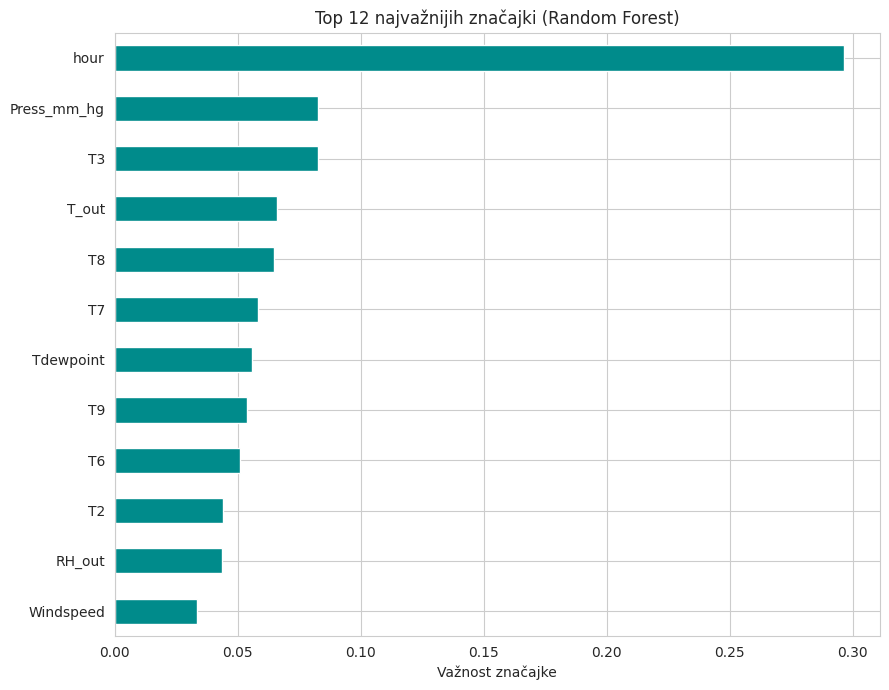

hour           0.2963
Press_mm_hg    0.0827
T3             0.0826
T_out          0.0658
T8             0.0647
T7             0.0583
Tdewpoint      0.0558
T9             0.0538
T6             0.0511
T2             0.0441
RH_out         0.0437
Windspeed      0.0336
T1             0.0329
Visibility     0.0282
is_weekend     0.0063
dtype: float64


In [ ]:
# Feature importance za Random Forest
importances = pd.Series(rf_reg.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 7))
importances.head(12).plot(kind='barh', color='darkcyan')
plt.gca().invert_yaxis()
plt.xlabel('Važnost značajke')
plt.title('Top 12 najvažnijih značajki (Random Forest)')
plt.tight_layout()
plt.show()

print(importances.round(4))

### 5.3 Primjena modela — interaktivno sučelje

In [ ]:
import ipywidgets as widgets
from IPython.display import display

# Ulazne kontrole
w_T1 = widgets.FloatSlider(value=19.0, min=14.0, max=30.0, step=0.5, description='T1 (kuhinja):')
w_T2 = widgets.FloatSlider(value=19.0, min=14.0, max=30.0, step=0.5, description='T2 (dnevna):')
w_T3 = widgets.FloatSlider(value=19.0, min=14.0, max=30.0, step=0.5, description='T3 (soba):')
w_T6 = widgets.FloatSlider(value=7.0, min=-5.0, max=30.0, step=0.5, description='T6 (van-kuća):')
w_T7 = widgets.FloatSlider(value=17.0, min=10.0, max=30.0, step=0.5, description='T7 (kupaona):')
w_T8 = widgets.FloatSlider(value=22.0, min=15.0, max=35.0, step=0.5, description='T8 (tinejdžer):')
w_T9 = widgets.FloatSlider(value=19.0, min=14.0, max=30.0, step=0.5, description='T9 (roditeljska):')
w_T_out = widgets.FloatSlider(value=6.0, min=-10.0, max=25.0, step=0.5, description='T vani:')
w_Tdew = widgets.FloatSlider(value=2.0, min=-10.0, max=15.0, step=0.5, description='Tdewpoint:')
w_Wind = widgets.FloatSlider(value=4.0, min=0.0, max=15.0, step=0.5, description='Vjetar (m/s):')
w_Vis = widgets.FloatSlider(value=40.0, min=1.0, max=66.0, step=1.0, description='Vidljivost:')
w_RH_out = widgets.FloatSlider(value=75.0, min=20.0, max=100.0, step=1.0, description='Vlažnost vani:')
w_Press = widgets.FloatSlider(value=733.0, min=729.0, max=772.0, step=0.5, description='Tlak (mm Hg):')
w_hour = widgets.IntSlider(value=18, min=0, max=23, step=1, description='Sat u danu:')
w_weekend = widgets.Dropdown(options=[('Radni dan', 0), ('Vikend', 1)], value=0, description='Dan:')

predict_button = widgets.Button(description='Procijeni potrošnju', button_style='success')
output_box = widgets.Output()

def on_predict(b):
    output_box.clear_output()
    input_dict = {
        'T1': w_T1.value, 'T2': w_T2.value, 'T3': w_T3.value,
        'T6': w_T6.value, 'T7': w_T7.value, 'T8': w_T8.value, 'T9': w_T9.value,
        'T_out': w_T_out.value, 'Tdewpoint': w_Tdew.value,
        'Windspeed': w_Wind.value, 'Visibility': w_Vis.value,
        'RH_out': w_RH_out.value, 'Press_mm_hg': w_Press.value,
        'hour': w_hour.value, 'is_weekend': w_weekend.value
    }
    input_df = pd.DataFrame([input_dict])[X_train.columns]
    pred = rf_reg.predict(input_df)[0]
    with output_box:
        print(f"Procijenjena potrošnja uređaja: {pred:.1f} Wh")

predict_button.on_click(on_predict)

ui = widgets.VBox([
    widgets.HTML("<h4>Unesite uvjete:</h4>"),
    widgets.HBox([
        widgets.VBox([w_T1, w_T2, w_T3, w_T6, w_T7, w_T8, w_T9]),
        widgets.VBox([w_T_out, w_Tdew, w_Wind, w_Vis, w_RH_out, w_Press, w_hour, w_weekend])
    ]),
    predict_button,
    output_box
])

display(ui)

## Zaključak

Za predviđanje potrošnje energije kućanskih uređaja koristio sam dataset "Appliances Energy Prediction" sa Kaggle-a. Iz podataka sam izbacio nasumične varijable (`rv1`, `rv2`) i iz stupca datuma izvukao korisne značajke (sat u danu, je li vikend). EDA je pokazala da potrošnja slijedi jasan dnevni obrazac (vrhunac navečer) te da temperatura u prostorijama i vanjska temperatura imaju najjači utjecaj. Isprobao sam tri modela — linearnu regresiju, regresijsko stablo i Random Forest — od kojih se Random Forest pokazao najboljim i najstabilnijim prema rezultatima kros-validacije i finalnim metrikama na test skupu.